# Example Notebook

## Populate

We can generate a populaiton of pulsars using populatenew

In [3]:
import sys
from pathlib import Path
module_dir = Path("lib/python").resolve()
sys.path.insert(0, str(module_dir))


import populate_new

A few parameters and examples.

`ngen` number of pulsars in population 

`savepop=True`
`savefile='pulsarpop.pkl'` save a file with population

`pDistType='lnorm'` period distrubtion type (lnorm, unif, norm, cc97, amma, lormier12)

`pDistPars=[2.7, -0.34]` period param i.e mu sigma

`radialDistType='lfl06'`, radial dist and parameters ('lfl06', 'yk04', 'isotropic','slab', 'disk','unif' ,'gauss','d_g', 'gamma')


`electronModel='ne2001_F'`, electron model ('ne2001', 'lmt85','ymw16','ne2025','ne2001_F','ne2025_F') the _F is for the Fortran version


`lumDistType='lnorm'`, luminsoity dist ('lnorm', 'log_unif', 'log_std')

` lumDistPars=[-1.1, 0.9]`, lum params

`nostdout=False`, don't print output

`bns = False`, make binary systems with uniform paramters
`orbparams = {'m': [1, 5], 'm1': [1.0, 2.4], 'm2': [0.2, 1e9], 'om': [0, 360.], 'inc': [0, 90], 'ec': [0., 1.], 'pod': [1e-3, 1e3]},`

In [4]:
pulsars = populate_new.generate(2000,pDistType='lnorm',lumDistType='lnorm',electronModel='ne2001_F',radialDistType='lfl06',bns = True,dither=False)

Binary


Saved population as pulsarpop.pkl


In [3]:
import pickle
#read the pkl file
with open("pulsarpop.pkl", "rb") as f:
    pop = pickle.load(f)

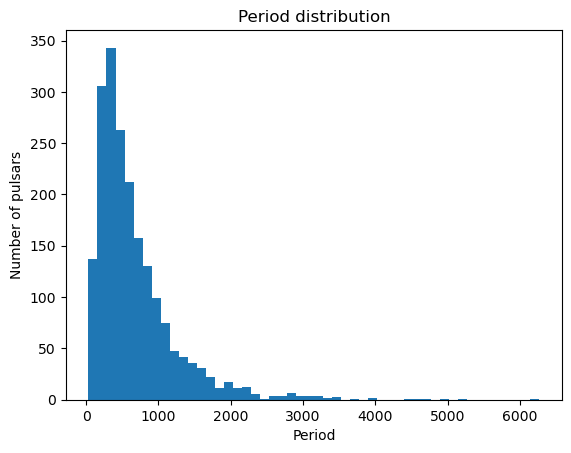

In [4]:
import matplotlib.pyplot as plt
#see the period dist
periods = [p.period for p in pop.population]

plt.hist(periods, bins=50)
plt.xlabel("Period")
plt.ylabel("Number of pulsars")
plt.title("Period distribution")
plt.show()

## Evolve

We can also get an evolved population.

In [5]:
import evolve_new

`age_max=1.0E9`, max age of the population
                    
`bFieldPars=[12.65, 0.55]`, magnetic field params

`birthVPars=[0.0, 180.]`, birth velocity 

`birthVModel='gaussian'`,
             
`spinModel='fk06'`, spindown model ('fk06','tk01','cs06')

`electronModel='ne2001_F'`, electron model ('ne2001', 'lmt85','ymw16','ne2025','ne2001_F','ne2025_F') the _F is for the Fortran version

           
             

In [6]:
psr = evolve_new.generate(10000,age_max=10**4.5)

1691 pulsar alive and beaming
	Generating evolved pulsars with parameters:
		ngen = 1691
		Using electron distn model ne2001_F

		Period mean, sigma = 2.7, 0.34
		Luminosity mean, sigma = -1.5, 0.5
		Spectral index mean, sigma = -1.6, 0.35
		Galactic z scale height = 0.05 kpc
		Width 5.0% 
Saved population as pulsarevo.pkl


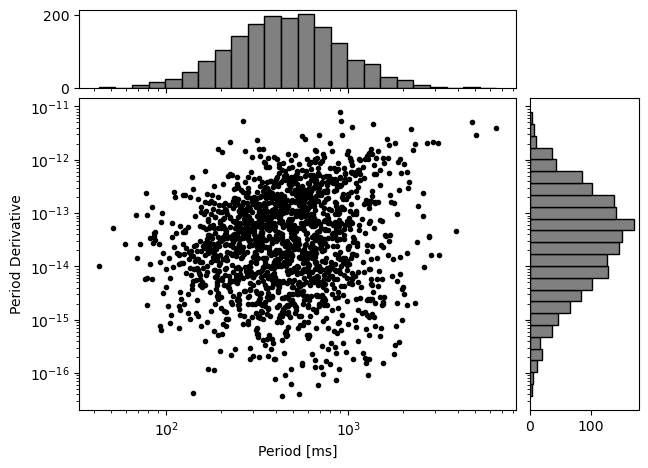

In [7]:
import numpy as np
import matplotlib.pyplot as plt
p = [p.period for p in psr]
pdot = [p.pdot for p in psr]



#making a histogram with scatter
def scatter_hist(x, y, ax, ax_histx, ax_histy):
    # no labels
    ax_histx.tick_params(axis="x",labelbottom=False)
    ax_histy.tick_params(axis="y",labelleft=False)
    ax.set_xlabel('Period [ms]') 
    ax.set_ylabel('Period Derivative')
    ax.set_xscale('log')
    ax.set_yscale('log')


    # the scatter plot:
    ax.scatter(x, y,color='k',marker='.')

    # now determine nice limits by hand:
    binx=(np.logspace(np.log10(x.min()), np.log10(x.max()), num=25))
    biny=(np.logspace(np.log10(y.min()), np.log10(y.max()), num=25))
    ax_histx.hist(x, ec="black",bins=binx,color='grey')
    ax_histy.hist(y, orientation='horizontal',ec="black",bins=biny,color='grey')
    
# Start with a square Figure.
fig = plt.figure(figsize=(7, 5))
# Add a gridspec with two rows and two columns and a ratio of 1 to 4 between
# the size of the marginal axes and the main axes in both directions.
# Also adjust the subplot parameters for a square plot.
gs = fig.add_gridspec(2, 2,  width_ratios=(4, 1), height_ratios=(1, 4),
                      left=0.1, right=0.9, bottom=0.1, top=0.9,
                      wspace=0.05, hspace=0.05)
# Create the Axes.
ax = fig.add_subplot(gs[1, 0])
ax_histx = fig.add_subplot(gs[0, 0], sharex=ax)
ax_histy = fig.add_subplot(gs[1, 1], sharey=ax)
x=np.array(p)
y=np.array(pdot)
# Draw the scatter plot and marginals.
scatter_hist(x, y, ax, ax_histx, ax_histy)
plt.savefig('p-pdot.png');plt.show();plt.close()

## Survey

Survey either popoulation.

In [8]:
import dosurvey_new

`pop`, population to survey

`surveyList`, list of survey files from `\lib\surveys`

`compute_degfac=False`, compute the orbital degredation factor for binary pulsars from Bachi et al 2013

`accelsearch=False`, deg factor for accel search

`jerksearch=False`, deg factor for jerk search

In [9]:
surveys_list=['DSA_1650_allsky']
pop1 = dosurvey_new.loadModel(popfile='pulsarevo.pkl') # pulsarpop.pkl
surveyPops = dosurvey_new.run( pop=pop1, surveyList=surveys_list,compute_degfac=False)

Loaded 1691 pulsars
Running doSurvey on population...


Running survey DSA_1650_allsky
Total pulsars in model = 1691
Number detected by survey DSA_1650_allsky = 562
Of which are discoveries = 562
Number too faint = 286
Number smeared = 843
Number out = 0


